# Table of Contents
- [6.0 Introduction: why linear algebra?](#intro)
- [6.1 Gaussian elimination and back substitution](#gauss)
- [6.2 Pivoting](#pivot)
- [6.3 LU decomposition](#lu)
- [6.4 Conditioning: when the answer can't be trusted](#cond)
- [6.5 Tridiagonal systems and the Thomas algorithm](#thomas)
- [6.6 Iterative methods: Jacobi, Gauss-Seidel and SOR](#iterative)
- [6.7 Eigenvalue problems: power iteration](#power)
- [6.8 Inverse iteration and the professional tools](#eig)
- [6.9 Least squares (a preview of Chapter 9)](#lstsq)
- [Problems](#problems)

# 6.0 Introduction: why linear algebra? <a class="anchor" id="intro"></a>
Systems of linear equations $A\mathbf{x}=\mathbf{b}$ and eigenvalue problems $A\mathbf{v}=\lambda\mathbf{v}$ are the beating heart of computational physics, even when the original problem looked nothing like a matrix:

- Kirchhoff's laws for a circuit give $A\mathbf{x}=\mathbf{b}$ directly.
- Discretising a differential equation with finite differences (the $1,-2,1$ stencil of Chapter 4) turns it into a (huge) matrix equation.
- The time-independent Schrödinger equation $\hat H\psi=E\psi$ becomes a **matrix eigenvalue problem**.
- Normal modes of coupled oscillators, moments of inertia, stress tensors, Markov chains, Google's PageRank... all eigenvalue problems.

In this chapter we build the classic algorithms ourselves, then see how to use `numpy.linalg` and `scipy.linalg` properly.

In [1]:
# BLOCK 6.0.1
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=5, suppress=True)

# 6.1 Gaussian elimination and back substitution <a class="anchor" id="gauss"></a>
You did this by hand at school. To solve

$$\begin{pmatrix} 2 & 1 & -1 \\ -3 & -1 & 2 \\ -2 & 1 & 2\end{pmatrix}\begin{pmatrix}x\\y\\z\end{pmatrix} = \begin{pmatrix}8\\-11\\-3\end{pmatrix}$$

we subtract multiples of row 0 from the rows below to make zeros in column 0, then multiples of row 1 to clear column 1, and so on, until the matrix is **upper triangular**. Then **back substitution** solves the last equation first and works upwards:

$$x_{i} = \frac{1}{U_{ii}}\left(b_i - \sum_{j>i}U_{ij}x_j\right).$$

Elimination costs about $\tfrac{2}{3}n^3$ operations, so doubling the size of a system makes it 8 times slower.

In [2]:
# BLOCK 6.1.1
def gaussian_elimination(A, b):
    """Solve Ax = b by naive Gaussian elimination (no pivoting)."""
    A = A.astype(float).copy()
    b = b.astype(float).copy()
    n = len(b)
    # forward elimination
    for k in range(n - 1):
        for i in range(k + 1, n):
            factor = A[i, k] / A[k, k]
            A[i, k:] -= factor*A[k, k:]
            b[i] -= factor*b[k]
    return back_substitution(A, b)

def back_substitution(U, b):
    n = len(b)
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        x[i] = (b[i] - U[i, i+1:] @ x[i+1:]) / U[i, i]
    return x

A = np.array([[2, 1, -1], [-3, -1, 2], [-2, 1, 2]])
b = np.array([8, -11, -3])
print('our solution  :', gaussian_elimination(A, b))
print('numpy.linalg  :', np.linalg.solve(A, b))

our solution  : [ 2.  3. -1.]
numpy.linalg  : [ 2.  3. -1.]


The `@` operator is matrix multiplication (here, a dot product of a row with a vector).

# 6.2 Pivoting <a class="anchor" id="pivot"></a>
Naive elimination divides by $A_{kk}$, the **pivot**. If a pivot is zero the algorithm crashes; if it's merely *small*, round-off errors get amplified enormously. Try this innocent-looking system whose exact solution is very nearly $x=y=1$:

$$\begin{pmatrix}10^{-17} & 1\\ 1 & 1\end{pmatrix}\begin{pmatrix}x\\y\end{pmatrix}=\begin{pmatrix}1\\2\end{pmatrix}$$

In [3]:
# BLOCK 6.2.1
A_bad = np.array([[1e-17, 1.0], [1.0, 1.0]])
b_bad = np.array([1.0, 2.0])
print('naive elimination:', gaussian_elimination(A_bad, b_bad))

naive elimination: [0. 1.]


Completely wrong! The fix, **partial pivoting**, is simple: before eliminating column $k$, swap rows so that the entry with the *largest magnitude* in that column becomes the pivot.

In [4]:
# BLOCK 6.2.2
def gauss_pivot(A, b):
    A = A.astype(float).copy()
    b = b.astype(float).copy()
    n = len(b)
    for k in range(n - 1):
        p = k + np.argmax(np.abs(A[k:, k]))     # row of the largest pivot
        if p != k:
            A[[k, p]] = A[[p, k]]               # swap rows k and p
            b[[k, p]] = b[[p, k]]
        for i in range(k + 1, n):
            factor = A[i, k] / A[k, k]
            A[i, k:] -= factor*A[k, k:]
            b[i] -= factor*b[k]
    return back_substitution(A, b)

print('with pivoting    :', gauss_pivot(A_bad, b_bad))

with pivoting    : [1. 1.]


# 6.3 LU decomposition <a class="anchor" id="lu"></a>
Very often we need to solve $A\mathbf{x}=\mathbf{b}$ for the same $A$ but many different $\mathbf{b}$ (e.g. every time step of an implicit PDE solver). Elimination is really a factorisation $A = LU$ in disguise, where $U$ is the upper triangular result and $L$ is lower triangular with the `factor`s stored below a diagonal of ones. Once we have $L$ and $U$, each new right-hand side costs only $\mathcal{O}(n^2)$:

$$A\mathbf{x} = L(U\mathbf{x}) = \mathbf{b}: \quad \text{solve } L\mathbf{y}=\mathbf{b} \text{ (forward substitution), then } U\mathbf{x}=\mathbf{y} \text{ (back substitution).}$$

In [5]:
# BLOCK 6.3.1
def lu_decompose(A):
    """Doolittle LU decomposition without pivoting: returns L, U with A = L U."""
    n = A.shape[0]
    U = A.astype(float).copy()
    L = np.eye(n)
    for k in range(n - 1):
        for i in range(k + 1, n):
            L[i, k] = U[i, k] / U[k, k]
            U[i, k:] -= L[i, k]*U[k, k:]
    return L, U

def forward_substitution(L, b):
    n = len(b)
    y = np.zeros(n)
    for i in range(n):
        y[i] = (b[i] - L[i, :i] @ y[:i]) / L[i, i]
    return y

L, U = lu_decompose(A)
print('L =\n', L, '\nU =\n', U, '\nL @ U =\n', L @ U)
for rhs in [b, np.array([1, 0, 0]), np.array([0, 1, 0])]:
    print('rhs', rhs, '-> x =', back_substitution(U, forward_substitution(L, rhs)))

L =
 [[ 1.   0.   0. ]
 [-1.5  1.   0. ]
 [-1.   4.   1. ]] 
U =
 [[ 2.   1.  -1. ]
 [ 0.   0.5  0.5]
 [ 0.   0.  -1. ]] 
L @ U =
 [[ 2.  1. -1.]
 [-3. -1.  2.]
 [-2.  1.  2.]]
rhs [  8 -11  -3] -> x = [ 2.  3. -1.]
rhs [1 0 0] -> x = [ 4. -2.  5.]
rhs [0 1 0] -> x = [ 3. -2.  4.]


`scipy.linalg.lu_factor` / `lu_solve` do the same thing (with pivoting) in optimised Fortran.

In [6]:
# BLOCK 6.3.2
from scipy import linalg
lu, piv = linalg.lu_factor(A)
print(linalg.lu_solve((lu, piv), b))

[ 2.  3. -1.]


# 6.4 Conditioning: when the answer can't be trusted <a class="anchor" id="cond"></a>
Some problems are intrinsically sensitive: a tiny change in $\mathbf{b}$ (e.g. measurement error) produces a huge change in $\mathbf{x}$. The **condition number** $\kappa(A)=\|A\|\,\|A^{-1}\|$ measures this:

$$\frac{\|\delta\mathbf{x}\|}{\|\mathbf{x}\|} \lesssim \kappa(A)\frac{\|\delta\mathbf{b}\|}{\|\mathbf{b}\|}.$$

A rough rule: you lose $\log_{10}\kappa$ decimal digits. No algorithm can fix an ill-conditioned problem - you need to reformulate it. The notorious example is the Hilbert matrix $H_{ij}=1/(i+j+1)$, which appears when fitting polynomials with least squares.

Never compute `np.linalg.inv(A) @ b` to solve a system - it's slower and less accurate than `np.linalg.solve(A, b)`.

In [7]:
# BLOCK 6.4.1
for n in [4, 8, 12, 16]:
    H = linalg.hilbert(n)
    x_true = np.ones(n)
    x = np.linalg.solve(H, H @ x_true)
    print(f'n = {n:>2}: cond = {np.linalg.cond(H):.1e},  max error in x = {np.max(np.abs(x - x_true)):.1e}')

n =  4: cond = 1.6e+04,  max error in x = 6.6e-14
n =  8: cond = 1.5e+10,  max error in x = 1.2e-07
n = 12: cond = 1.8e+16,  max error in x = 7.0e-01
n = 16: cond = 3.0e+17,  max error in x = 1.0e+01


# 6.5 Tridiagonal systems and the Thomas algorithm <a class="anchor" id="thomas"></a>
Let's solve a physics BVP by turning it into a matrix. **Poisson's equation** in 1D, $\phi''(x) = -\rho(x)/\varepsilon_0$, with $\phi(0)=\phi(L)=0$. Using the second-derivative stencil on $N$ interior grid points:

$$\frac{\phi_{i-1} - 2\phi_i + \phi_{i+1}}{h^2} = -\frac{\rho_i}{\varepsilon_0}.$$

Each equation only involves three neighbouring unknowns, so the matrix is **tridiagonal** - zero everywhere except the main diagonal and its two neighbours. Gaussian elimination on a tridiagonal matrix only ever touches those three diagonals, and the cost drops from $\mathcal{O}(n^3)$ to $\mathcal{O}(n)$! This special case is called the **Thomas algorithm**.

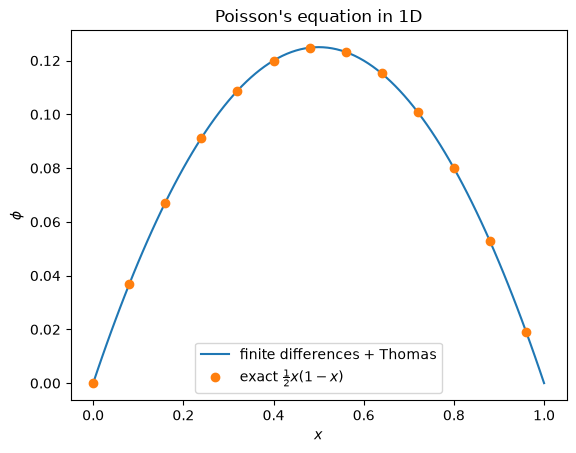

In [8]:
# BLOCK 6.5.1
def thomas(a, b, c, d):
    """Solve a tridiagonal system. a = sub-diagonal (len n-1), b = diagonal (n),
    c = super-diagonal (n-1), d = right-hand side (n)."""
    n = len(d)
    cp, dp = np.zeros(n - 1), np.zeros(n)
    cp[0], dp[0] = c[0]/b[0], d[0]/b[0]
    for i in range(1, n):
        denom = b[i] - a[i-1]*cp[i-1]
        if i < n - 1:
            cp[i] = c[i]/denom
        dp[i] = (d[i] - a[i-1]*dp[i-1]) / denom
    x = np.zeros(n)
    x[-1] = dp[-1]
    for i in range(n - 2, -1, -1):
        x[i] = dp[i] - cp[i]*x[i+1]
    return x

# Uniformly charged slab between two grounded plates (units with eps0 = 1, rho = 1, L = 1)
N = 99
x = np.linspace(0, 1, N + 2)
h = x[1] - x[0]
rho = np.ones(N)
phi_inner = thomas(np.ones(N-1), -2*np.ones(N), np.ones(N-1), -rho*h**2)
phi = np.concatenate([[0], phi_inner, [0]])

plt.plot(x, phi, label='finite differences + Thomas')
plt.plot(x[::8], 0.5*x[::8]*(1 - x[::8]), 'o', label=r'exact $\frac{1}{2}x(1-x)$')
plt.xlabel('$x$'); plt.ylabel(r'$\phi$'); plt.legend(); plt.title("Poisson's equation in 1D")
plt.show()

For general sparse matrices use `scipy.sparse` and `scipy.sparse.linalg.spsolve`; for banded ones `scipy.linalg.solve_banded`.

# 6.6 Iterative methods: Jacobi, Gauss-Seidel and SOR <a class="anchor" id="iterative"></a>
For enormous sparse systems (millions of unknowns - e.g. a 3D grid) even storing $L$ and $U$ is too expensive. Iterative methods start with a guess and repeatedly improve it, only ever needing to multiply by $A$.

Split row $i$ of $A\mathbf{x}=\mathbf{b}$ to isolate the diagonal term:

- **Jacobi:** $\displaystyle x_i^{(k+1)} = \frac{1}{A_{ii}}\Big(b_i - \sum_{j\ne i}A_{ij}x_j^{(k)}\Big)$ - use only old values.
- **Gauss-Seidel:** same, but use *new* values as soon as they are computed. Usually twice as fast as Jacobi.
- **Successive over-relaxation (SOR):** over-shoot the Gauss-Seidel update by a factor $1<\omega<2$: $x_i \leftarrow (1-\omega)x_i + \omega\,x_i^{GS}$. With the optimal $\omega$ it can be dramatically faster.

These converge if $A$ is *diagonally dominant* ($|A_{ii}|>\sum_{j\neq i}|A_{ij}|$) or symmetric positive-definite. Look familiar? These are just the rearrangement iterations $x_{n+1}=\varrho(x_n)$ of Chapter 3, in many dimensions.

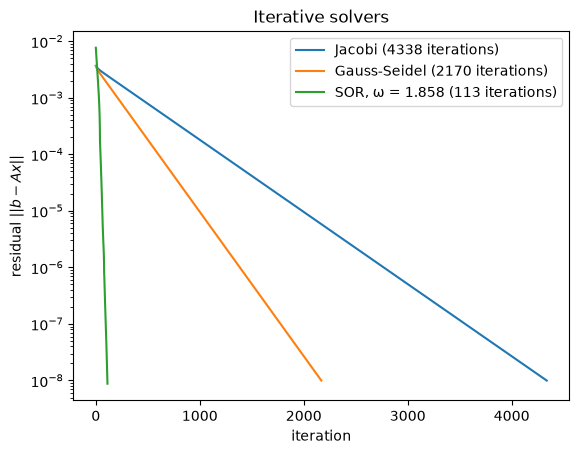

In [9]:
# BLOCK 6.6.1
def sor(A, b, omega=1.0, tol=1e-8, max_iter=20000):
    """omega = 1 gives Gauss-Seidel. Returns (x, residual history)."""
    n = len(b)
    x = np.zeros(n)
    history = []
    for k in range(max_iter):
        for i in range(n):
            sigma = A[i, :i] @ x[:i] + A[i, i+1:] @ x[i+1:]
            x[i] = (1 - omega)*x[i] + omega*(b[i] - sigma)/A[i, i]
        res = np.linalg.norm(b - A @ x)
        history.append(res)
        if res < tol:
            break
    return x, history

def jacobi(A, b, tol=1e-8, max_iter=20000):
    D = np.diag(A)
    R = A - np.diag(D)
    x = np.zeros(len(b))
    history = []
    for k in range(max_iter):
        x = (b - R @ x) / D           # fully vectorised: every x_i updated from old values
        res = np.linalg.norm(b - A @ x)
        history.append(res)
        if res < tol:
            break
    return x, history

# The Poisson matrix again, smaller this time
n = 40
A_p = -2*np.eye(n) + np.eye(n, k=1) + np.eye(n, k=-1)
b_p = -np.ones(n)/(n + 1)**2
omega_opt = 2/(1 + np.sin(np.pi/(n + 1)))          # known optimum for this matrix

for label, (sol, hist) in {'Jacobi': jacobi(A_p, b_p),
                           'Gauss-Seidel': sor(A_p, b_p, 1.0),
                           f'SOR, ω = {omega_opt:.3f}': sor(A_p, b_p, omega_opt)}.items():
    plt.semilogy(hist, label=f'{label} ({len(hist)} iterations)')
plt.xlabel('iteration'); plt.ylabel('residual $||b - Ax||$'); plt.legend(); plt.title('Iterative solvers')
plt.show()

We'll use exactly these relaxation methods to solve Laplace's equation in 2D in Chapter 7.

# 6.7 Eigenvalue problems: power iteration <a class="anchor" id="power"></a>
Take any vector $\mathbf{x}_0$ and expand it in the eigenvectors of $A$: $\mathbf{x}_0=\sum_i c_i\mathbf{v}_i$. Multiplying by $A$ $k$ times gives

$$A^k\mathbf{x}_0 = \sum_i c_i\lambda_i^k\mathbf{v}_i = \lambda_1^k\Big(c_1\mathbf{v}_1 + \sum_{i>1}c_i\big(\tfrac{\lambda_i}{\lambda_1}\big)^k\mathbf{v}_i\Big).$$

If $|\lambda_1|$ is the largest eigenvalue, all other terms die away and $A^k\mathbf{x}_0$ points along $\mathbf{v}_1$. That's **power iteration**: repeatedly multiply and normalise. The eigenvalue is then given by the **Rayleigh quotient** $\lambda\approx\mathbf{x}^T A\mathbf{x}/\mathbf{x}^T\mathbf{x}$. Convergence is governed by the ratio $|\lambda_2/\lambda_1|$.

**Physics example: normal modes.** Three equal masses $m$ joined by four identical springs $k$ between two walls. Newton's law gives $m\ddot{\mathbf{x}} = -K\mathbf{x}$ with

$$K = k\begin{pmatrix}2&-1&0\\-1&2&-1\\0&-1&2\end{pmatrix}.$$

Trying $\mathbf{x}=\mathbf{v}e^{i\omega t}$ gives the eigenvalue problem $K\mathbf{v}=m\omega^2\mathbf{v}$.

In [10]:
# BLOCK 6.7.1
def power_iteration(A, tol=1e-12, max_iter=10000):
    x = np.random.default_rng(0).random(A.shape[0])
    lam_old = 0
    for k in range(max_iter):
        x = A @ x
        x /= np.linalg.norm(x)
        lam = x @ A @ x                       # Rayleigh quotient
        if abs(lam - lam_old) < tol:
            break
        lam_old = lam
    return lam, x, k + 1

K = np.array([[2, -1, 0], [-1, 2, -1], [0, -1, 2]], dtype=float)   # k = m = 1
lam, v, its = power_iteration(K)
print(f'largest omega^2 = {lam:.10f} after {its} iterations (exact 2 + sqrt 2 = {2 + np.sqrt(2):.10f})')
print('mode shape:', v / v[0])

largest omega^2 = 3.4142135624 after 29 iterations (exact 2 + sqrt 2 = 3.4142135624)
mode shape: [ 1.      -1.41421  1.     ]


# 6.8 Inverse iteration and the professional tools <a class="anchor" id="eig"></a>
Usually we want the **smallest** eigenvalues (the ground state, the lowest modes). The eigenvalues of $(A-\sigma I)^{-1}$ are $1/(\lambda_i-\sigma)$, so power iteration on that matrix finds the eigenvalue **closest to the shift $\sigma$**. Don't form the inverse - solve $(A-\sigma I)\mathbf{x}_{k+1}=\mathbf{x}_k$ with a pre-computed LU factorisation.

For whole spectra of dense matrices, `numpy.linalg.eigh` (for symmetric/Hermitian matrices - always prefer it when it applies) and `numpy.linalg.eig` (general matrices) use the QR algorithm. For large sparse matrices where you need only a few eigenvalues, `scipy.sparse.linalg.eigsh` is the tool.

smallest omega^2 = 0.5857864376 (exact 2 - sqrt 2 = 0.5857864376)
all omega^2 from eigh: [0.58579 2.      3.41421]


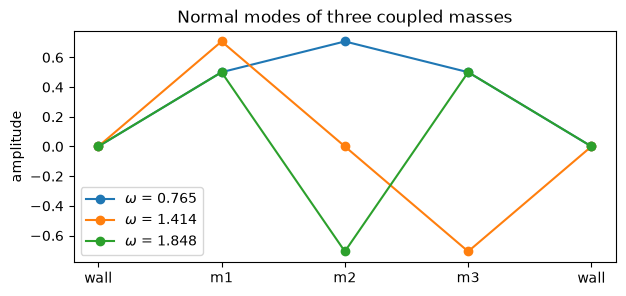

In [11]:
# BLOCK 6.8.1
def inverse_iteration(A, sigma=0.0, tol=1e-12, max_iter=1000):
    n = A.shape[0]
    lu = linalg.lu_factor(A - sigma*np.eye(n))
    x = np.ones(n)
    lam_old = np.inf
    for k in range(max_iter):
        x = linalg.lu_solve(lu, x)
        x /= np.linalg.norm(x)
        lam = x @ A @ x
        if abs(lam - lam_old) < tol:
            break
        lam_old = lam
    return lam, x

lam_min, v_min = inverse_iteration(K)
print(f'smallest omega^2 = {lam_min:.10f} (exact 2 - sqrt 2 = {2 - np.sqrt(2):.10f})')

w2, V = np.linalg.eigh(K)
print('all omega^2 from eigh:', w2)

fig, ax = plt.subplots(figsize=(7, 3))
for j in range(3):
    ax.plot([0, 1, 2, 3, 4], np.r_[0, V[:, j], 0] * (1 if V[0, j] > 0 else -1), 'o-',
            label=fr'$\omega$ = {np.sqrt(w2[j]):.3f}')
ax.set_xticks(range(5)); ax.set_xticklabels(['wall', 'm1', 'm2', 'm3', 'wall'])
ax.set_ylabel('amplitude'); ax.legend(); ax.set_title('Normal modes of three coupled masses')
plt.show()

# 6.9 Least squares (a preview of Chapter 9) <a class="anchor" id="lstsq"></a>
What if there are *more* equations than unknowns, e.g. fitting a straight line through 50 noisy data points? There's no exact solution, but we can minimise $\|A\mathbf{x}-\mathbf{b}\|^2$. Setting the gradient to zero gives the **normal equations** $A^TA\mathbf{x}=A^T\mathbf{b}$, but these square the condition number, so `np.linalg.lstsq` uses the more stable QR or SVD decompositions instead.

In [12]:
# BLOCK 6.9.1
rng = np.random.default_rng(1)
t = np.linspace(0, 10, 50)
data = 3.0 + 0.5*t + rng.normal(0, 0.5, t.size)
A_fit = np.column_stack([np.ones_like(t), t])        # columns: 1, t
coeffs, *_ = np.linalg.lstsq(A_fit, data, rcond=None)
print(f'intercept = {coeffs[0]:.3f}, slope = {coeffs[1]:.3f}  (true values 3, 0.5)')

intercept = 3.043, slope = 0.488  (true values 3, 0.5)


# Problems <a class="anchor" id="problems"></a>

### Exercise 1 - A Wheatstone bridge
Write down Kirchhoff's laws for a Wheatstone bridge with resistors $R_1=R_2=R_3=100\,\Omega$, $R_4=110\,\Omega$, a $50\,\Omega$ galvanometer and a 10 V battery. Solve for all branch currents using `gauss_pivot` and check against `np.linalg.solve`.

### Exercise 2 - Timing
Generate random $n\times n$ systems for $n=50,100,200,400$. Time `gauss_pivot` and `np.linalg.solve` with `%timeit`. Plot time against $n$ on log-log axes and confirm the $n^3$ scaling. How much faster is numpy?

### Exercise 3 - A chain of $N$ masses
Generalise the normal-mode example to $N=50$ masses. Use `np.linalg.eigh` to find all frequencies and compare with the analytic result $\omega_j = 2\sqrt{k/m}\sin\!\left(\frac{j\pi}{2(N+1)}\right)$. Plot the lowest four mode shapes. What happens to the spectrum if the middle mass is made 10 times heavier? (Hint: you now have a *generalised* eigenvalue problem $K\mathbf{v}=\omega^2M\mathbf{v}$ - try `scipy.linalg.eigh(K, M)`.)

### Exercise 4 - Principal axes
The inertia tensor of a rigid body made of point masses $m_k$ at $\mathbf{r}_k$ is $I_{ij}=\sum_k m_k(r_k^2\delta_{ij}-r_{k,i}r_{k,j})$. Build it for a few random masses and find the principal moments and axes with `eigh`.

In [13]:
# Start working here

---
<details>
<summary>🥚</summary>

This is a deliberate easter egg, not part of the course, and nothing in it is examinable. Run the cell below.
</details>

In [14]:
# Easter egg (deliberate, not part of the course): the Fibonacci matrix [[1, 1], [1, 0]].
import math

# Its characteristic polynomial is lambda^2 - lambda - 1 = 0, so the eigenvalues are:
phi = (1 + math.sqrt(5))/2
psi = (1 - math.sqrt(5))/2
print(f"eigenvalues: {phi:.12f} and {psi:.12f}  (the big one is the golden ratio)")

# Diagonalising: [[1, 1], [1, 0]]^n = [[F(n+1), F(n)], [F(n), F(n-1)]], with F(n) = (phi^n - psi^n)/sqrt(5)
n = 30
F_eig = round((phi**n - psi**n)/math.sqrt(5))

def matmul(A, B):
    return [[A[0][0]*B[0][0] + A[0][1]*B[1][0], A[0][0]*B[0][1] + A[0][1]*B[1][1]],
            [A[1][0]*B[0][0] + A[1][1]*B[1][0], A[1][0]*B[0][1] + A[1][1]*B[1][1]]]

M = [[1, 0], [0, 1]]
for _ in range(n):                    # exact integer check by repeated multiplication
    M = matmul(M, [[1, 1], [1, 0]])
print(f"F({n}) = {F_eig} (from the eigenvalues) = {M[0][1]} (from the matrix power)")

eigenvalues: 1.618033988750 and -0.618033988750  (the big one is the golden ratio)
F(30) = 832040 (from the eigenvalues) = 832040 (from the matrix power)
